In [2]:
# Pandas Library is imported into the file Multiple Regression Exercise 1
import pandas as pd

In [5]:
# Variable l_dataset
# assign the read_csv function from pandas into the variable l_dataset
l_dataset = pd.read_csv("50_Startups.csv")

In [7]:
l_dataset3= pd.get_dummies(l_dataset, dtype=int)

In [9]:
#drop the first columm to avoid the duplication data
l_dataset3 = pd.get_dummies(l_dataset, dtype=int, drop_first=True)

In [11]:
l_dataset3

,R&D Spend,Administration,Marketing Spend,Profit,State_Florida,State_New York
0,165349.20,136897.80,471784.10,192261.83,0,1
1,162597.70,151377.59,443898.53,191792.06,0,0
2,153441.51,101145.55,407934.54,191050.39,1,0
3,144372.41,118671.85,383199.62,182901.99,0,1
4,142107.34,91391.77,366168.42,166187.94,1,0
5,131876.90,99814.71,362861.36,156991.12,0,1
6,134615.46,147198.87,127716.82,156122.51,0,0
7,130298.13,145530.06,323876.68,155752.60,1,0
8,120542.52,148718.95,311613.29,152211.77,0,1
9,123334.88,108679.17,304981.62,149759.96,0,0


In [13]:
independent=l_dataset3[['R&D Spend', 'Administration', 'Marketing Spend','State_Florida', 'State_New York']]

In [15]:
dependent = l_dataset3[["Profit"]]

In [16]:
from sklearn.model_selection import train_test_split
train_test_split (independent, dependent, test_size=0.30, random_state=0)

[    R&D Spend  Administration  Marketing Spend  State_Florida  State_New York
 7   130298.13       145530.06        323876.68              1               0
 14  119943.24       156547.42        256512.92              1               0
 45    1000.23       124153.04          1903.93              0               1
 48     542.05        51743.15             0.00              0               1
 29   65605.48       153032.06        107138.38              0               1
 15  114523.61       122616.84        261776.23              0               1
 30   61994.48       115641.28         91131.24              1               0
 32   63408.86       129219.61         46085.25              0               0
 16   78013.11       121597.55        264346.06              0               0
 42   23640.93        96189.63        148001.11              0               0
 20   76253.86       113867.30        298664.47              0               0
 43   15505.73       127382.30         35534.17     

In [17]:
X_train, X_test, y_train, y_test=train_test_split (independent, dependent, test_size=0.30,random_state=0)

In [63]:
# Model Creation
# criterion{“squared_error”, “absolute_error”, “poisson”}, default=”squared_error”
# splitter{“best”, “random”}, default=”best”
#1
# from sklearn.tree import DecisionTreeRegressor
# l_reg1=DecisionTreeRegressor()
#2
# from sklearn.tree import DecisionTreeRegressor
# l_reg1=DecisionTreeRegressor(criterion='squared_error')
#3
# from sklearn.tree import DecisionTreeRegressor
# l_reg1=DecisionTreeRegressor(criterion='squared_error',splitter='best')
#4
# from sklearn.tree import DecisionTreeRegressor
# l_reg1=DecisionTreeRegressor(criterion='squared_error',splitter='random')
#5
# from sklearn.tree import DecisionTreeRegressor
# l_reg1=DecisionTreeRegressor(criterion='absolute_error',splitter='random')
#6
# from sklearn.tree import DecisionTreeRegressor
# l_reg1=DecisionTreeRegressor(criterion='poisson',splitter='best')
#7
from sklearn.tree import DecisionTreeRegressor
l_reg1=DecisionTreeRegressor(criterion='poisson',splitter='random')



In [64]:
# Model creations and train the model
l_reg1=l_reg1.fit(X_train,y_train)

[Text(0.49320652173913043, 0.9444444444444444, 'x[0] <= 59374.507\npoisson = 9248.617\nsamples = 35\nvalue = 110225.321'),
 Text(0.29891304347826086, 0.8333333333333334, 'x[0] <= 41947.321\npoisson = 4562.86\nsamples = 12\nvalue = 62807.681'),
 Text(0.3960597826086957, 0.8888888888888888, 'True  '),
 Text(0.27717391304347827, 0.7222222222222222, 'x[0] <= 28155.442\npoisson = 4458.979\nsamples = 11\nvalue = 60340.275'),
 Text(0.18478260869565216, 0.6111111111111112, 'x[0] <= 6940.012\npoisson = 3955.918\nsamples = 8\nvalue = 51723.646'),
 Text(0.10869565217391304, 0.5, 'x[4] <= 0.444\npoisson = 3672.427\nsamples = 5\nvalue = 41466.274'),
 Text(0.06521739130434782, 0.3888888888888889, 'x[0] <= 1152.69\npoisson = 3655.889\nsamples = 3\nvalue = 35577.293'),
 Text(0.043478260869565216, 0.2777777777777778, 'x[1] <= 121864.672\npoisson = 3543.247\nsamples = 2\nvalue = 28620.565'),
 Text(0.021739130434782608, 0.16666666666666666, 'poisson = 0.0\nsamples = 1\nvalue = 14681.4'),
 Text(0.06521739

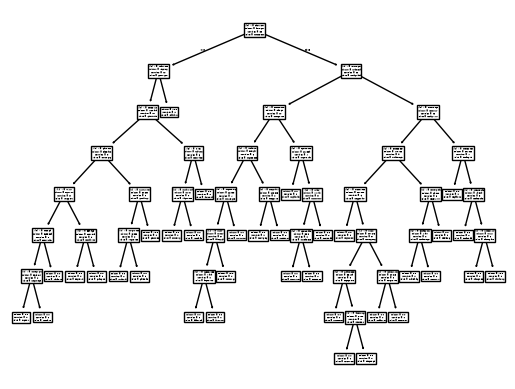

In [65]:
# Graph tree library
import matplotlib.pyplot as plt
from sklearn import tree
tree.plot_tree(l_reg1)

In [66]:
y_pred = l_reg1.predict (X_test)

In [67]:
y_pred

array([107404.34, 141585.52, 141585.52,  71498.49, 156991.12, 118474.03,
        71498.49, 101004.64, 108733.99, 156991.12,  89949.14,  89949.14,
       108552.04,  89949.14, 134307.35])

In [68]:
from sklearn.metrics import r2_score
l_score=r2_score (y_test, y_pred)
print(l_score)

0.8712696891320049
